# 本実験の楽曲選出：各クラスターの中心側・中間・外側から各4曲、計12曲をランダムに選出

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
local_csv = Path('acoustic_features_whole.csv')
if local_csv.exists():
    csv_path = local_csv
else:
    from google.colab import drive
    drive.mount('/content/drive')
    csv_path = Path('/content/drive/MyDrive/Colab Notebooks/実験用楽曲データ作成（手作り）/acoustic_features_whole.csv')
df = pd.read_csv(csv_path)
display(df.head())
print(df.isnull().sum())

,filename,rms,spectral_centroids,spectral_bandwidth,spectral_rolloff,mfcc_0,mfcc_1,mfcc_2,mfcc_3,mfcc_4,...,chroma_mean_D,chroma_mean_D#,chroma_mean_E,chroma_mean_F,chroma_mean_F#,chroma_mean_G,chroma_mean_G#,chroma_mean_A,chroma_mean_A#,chroma_mean_B
0,4361中_一定0_2x中,0.086683,2338.548859,3072.460259,4947.888011,-244.60947,147.53348,-11.589661,47.813587,-11.839340,...,0.207065,0.298755,0.639111,0.275838,0.167967,0.199051,0.200265,0.182823,0.178733,0.274818
1,4361中_一定0_2x大,0.086693,2459.148923,3133.289605,5177.942599,-238.44048,144.67245,-12.940132,48.444160,-12.700476,...,0.200997,0.297751,0.634766,0.275356,0.172157,0.203521,0.205968,0.191434,0.177823,0.271335
2,4361中_一定0_2x小,0.084644,1873.067253,2450.249798,3815.243089,-271.41330,166.13542,-13.992412,42.099655,-9.483488,...,0.216881,0.307218,0.652227,0.289543,0.166515,0.186503,0.178944,0.160457,0.166494,0.274580
3,4361中_一定0_drumn中,0.082511,2252.612283,3005.246255,4690.090972,-269.77190,150.14194,1.889258,32.047665,-11.998518,...,0.223040,0.312073,0.660884,0.295452,0.161604,0.180024,0.174185,0.159994,0.176516,0.285014
4,4361中_一定0_drumn大,0.083327,2238.573322,2925.990766,4652.265327,-262.07693,151.79042,-6.154371,37.770306,-12.583860,...,0.208908,0.300242,0.648869,0.284478,0.165057,0.191060,0.189757,0.174772,0.179346,0.283908


filename              0
rms                   0
spectral_centroids    0
spectral_bandwidth    0
spectral_rolloff      0
mfcc_0                0
mfcc_1                0
mfcc_2                0
mfcc_3                0
mfcc_4                0
mfcc_5                0
mfcc_6                0
mfcc_7                0
mfcc_8                0
mfcc_9                0
mfcc_10               0
mfcc_11               0
mfcc_12               0
mfcc_13               0
mfcc_14               0
mfcc_15               0
mfcc_16               0
mfcc_17               0
mfcc_18               0
mfcc_19               0
zcr                   0
low_peaks             0
middle_peaks          0
high_peaks            0
super_high_peaks      0
chroma_mean_C         0
chroma_mean_C#        0
chroma_mean_D         0
chroma_mean_D#        0
chroma_mean_E         0
chroma_mean_F         0
chroma_mean_F#        0
chroma_mean_G         0
chroma_mean_G#        0
chroma_mean_A         0
chroma_mean_A#        0
chroma_mean_B   

In [3]:
#主成分分析を行う
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

#数値データとfilenameを切り分ける
col_num = df.iloc[:, 1:].columns

df_num = df[col_num]
df_name = df['filename']

#標準化する
scaler = StandardScaler()
df_scaler = scaler.fit_transform(df_num)

#主成分分析する
n_comp = 7
pca = PCA(n_components=n_comp)
df_pca = pca.fit_transform(df_scaler)
df_pca = pd.DataFrame(df_pca, columns=[f'PC{i+1}' for i in range(n_comp)])

def split_metadata(df):
    df['harmony'] = df['filename'].apply(lambda x: x.split('_')[0])
    df['melody'] = df['filename'].apply(lambda x: x.split('_')[1])
    df['rhythm'] = df['filename'].apply(lambda x: x.split('_')[2])
    return df

df_final = df_pca.copy()
df_final['filename'] = df_name
df_final = split_metadata(df_final)
display(df_final.head())
#以降で各種情報を出力する

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,filename,harmony,melody,rhythm
0,4.859764,4.609546,4.082639,1.204484,1.753330,2.177085,1.238263,4361中_一定0_2x中,4361中,一定0,2x中
1,5.582600,4.520650,3.629085,0.820856,2.033143,1.723758,1.222517,4361中_一定0_2x大,4361中,一定0,2x大
2,0.623730,4.363242,3.930887,2.228263,2.003827,2.663163,0.806198,4361中_一定0_2x小,4361中,一定0,2x小
3,0.525530,4.492249,2.149991,-0.218717,3.126363,-0.372779,3.252083,4361中_一定0_drumn中,4361中,一定0,drumn中
4,1.152177,4.237613,2.036803,0.236783,3.476902,-0.080181,2.539778,4361中_一定0_drumn大,4361中,一定0,drumn大


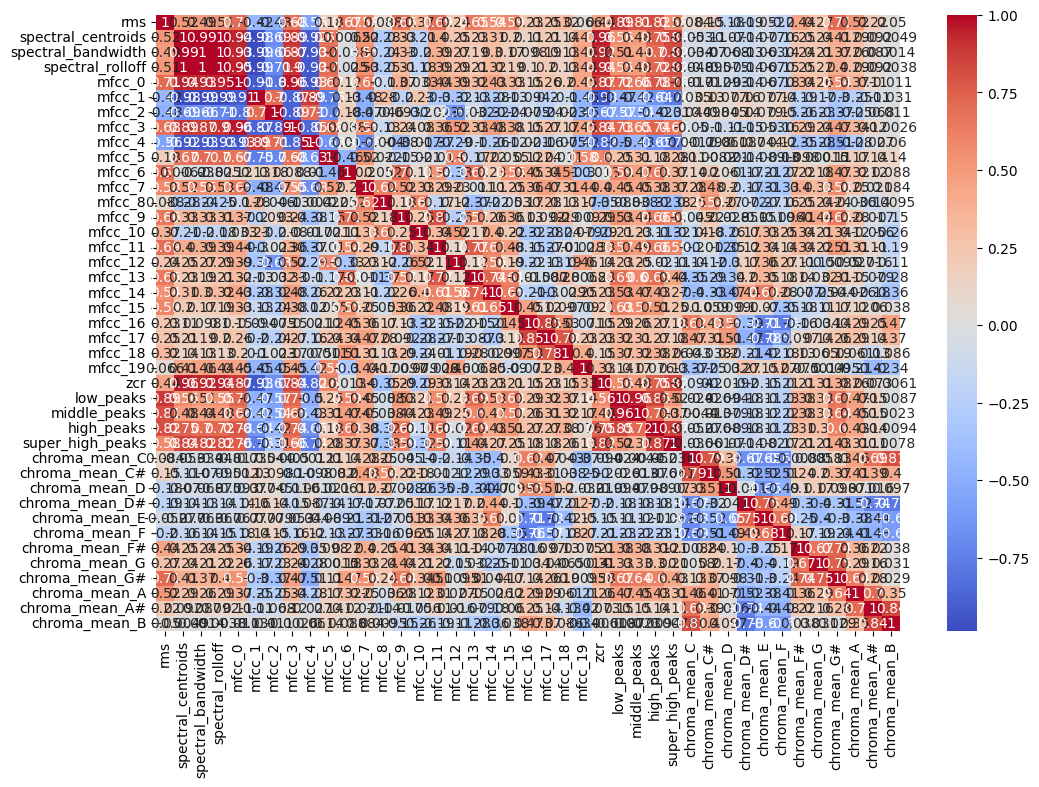

In [4]:
# 特徴量の相関行列を計算
df_scaler = pd.DataFrame(df_scaler, columns=col_num)
corr_matrix = df_scaler.corr()
# 相関行列のヒートマップを表示
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.show()

In [5]:
#主成分寄与率
print("主成分寄与率：", pca.explained_variance_ratio_)
print('累積寄与率：', np.cumsum(pca.explained_variance_ratio_))

主成分寄与率： [0.33754087 0.17635746 0.12436146 0.08329255 0.06960312 0.06423221
 0.04003051]
累積寄与率： [0.33754087 0.51389833 0.63825979 0.72155234 0.79115545 0.85538766
 0.89541817]


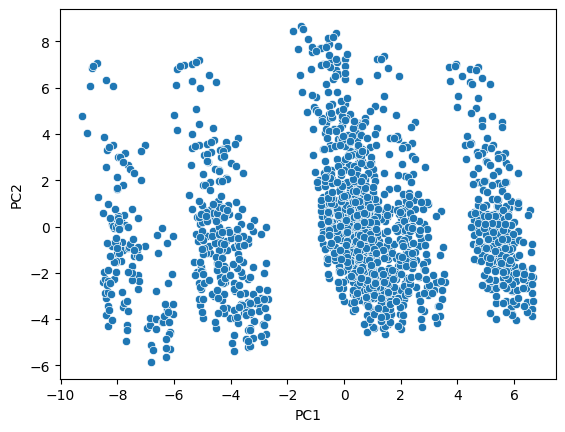

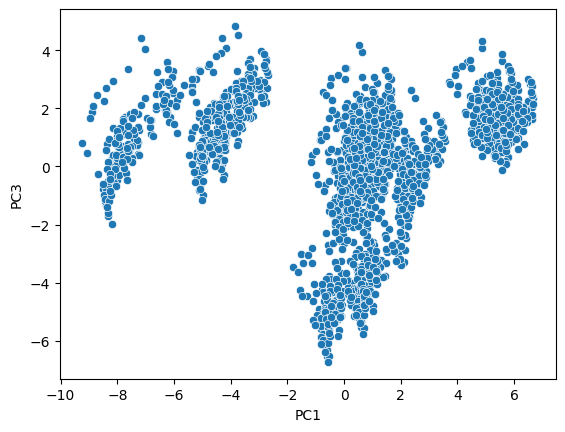

C:\Users\koyamaharuki\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 19968 (\N{CJK UNIFIED IDEOGRAPH-4E00}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\koyamaharuki\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 23450 (\N{CJK UNIFIED IDEOGRAPH-5B9A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\koyamaharuki\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 19978 (\N{CJK UNIFIED IDEOGRAPH-4E0A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\koyamaharuki\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 26119 (\N{CJK UNIFIED IDEOGRAPH-6607}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\koyamah

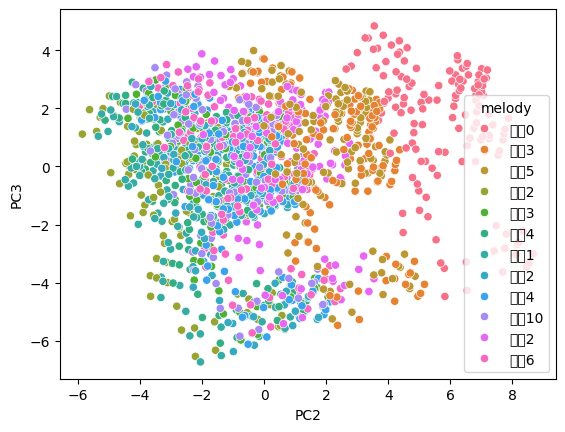

In [6]:
#pc1, pc2でプロット
sns.scatterplot(data=df_final, x='PC1', y='PC2')
plt.show()

#pc1, pc3でプロット
sns.scatterplot(data=df_final, x='PC1', y='PC3')
plt.show()

#pc2, pc3でプロット
sns.scatterplot(data=df_final, x='PC2', y='PC3', hue='melody')
plt.show()

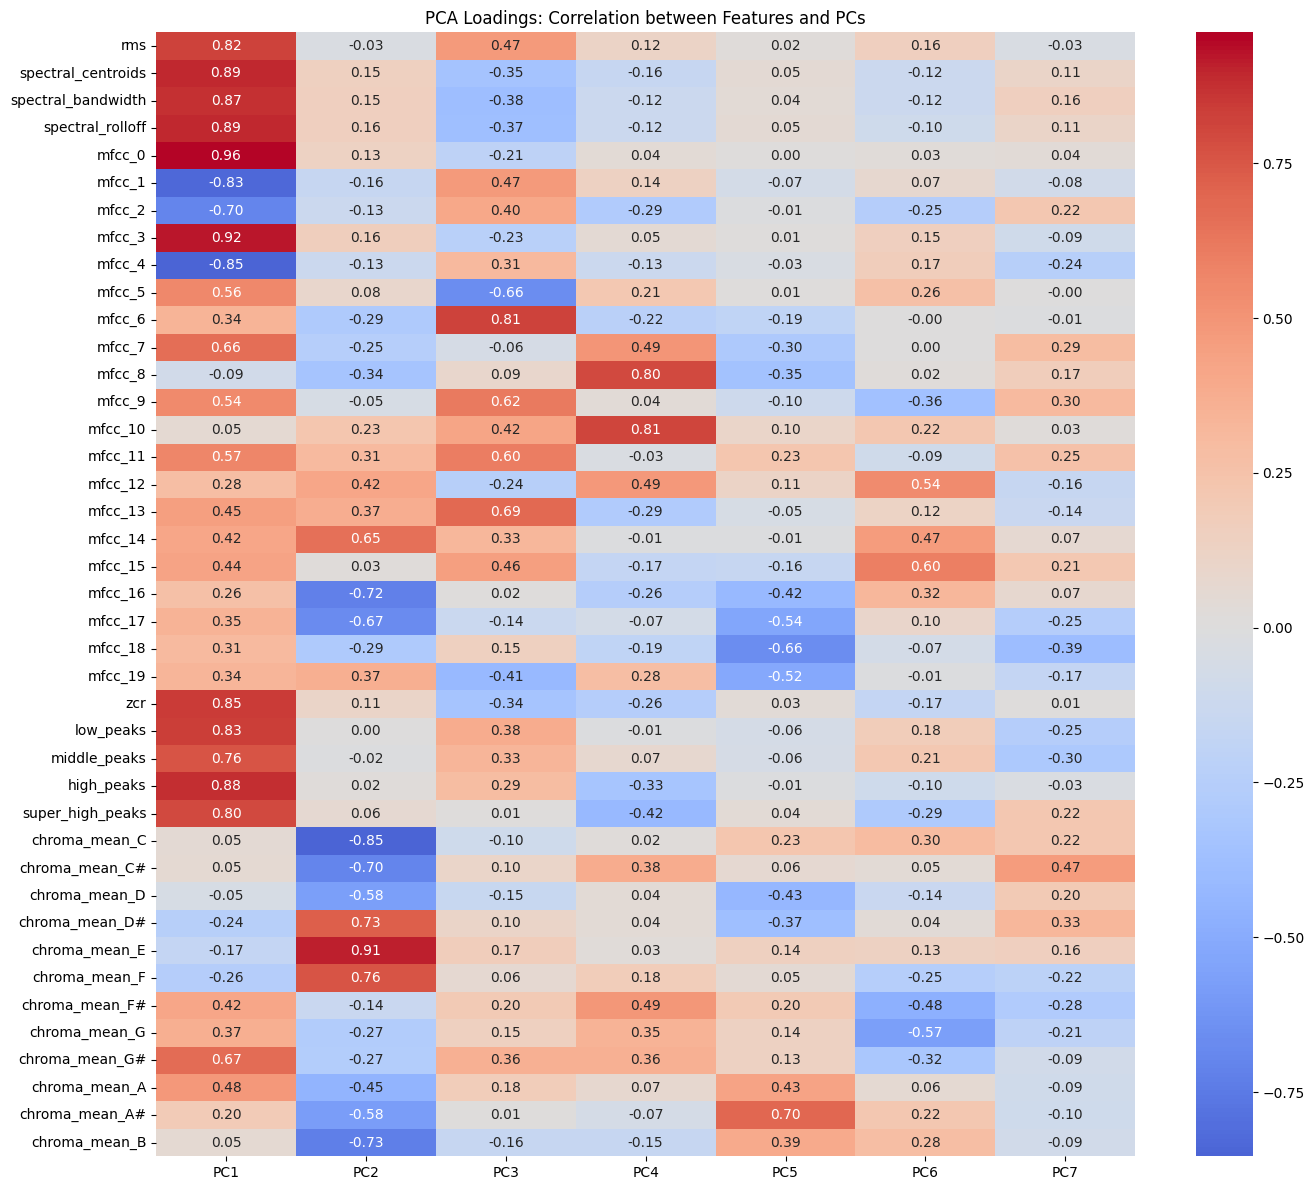

In [7]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# PC1〜PC4まで表示
n_pc_show = 7

# 相関loadingを計算
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)

loading_df = pd.DataFrame(
    loadings[:, :n_pc_show],
    index=col_num,
    columns=[f"PC{i}" for i in range(1, n_pc_show + 1)]
)

plt.figure(figsize=(14, 12))

sns.heatmap(
    loading_df,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("PCA Loadings: Correlation between Features and PCs")
plt.tight_layout()
plt.show()

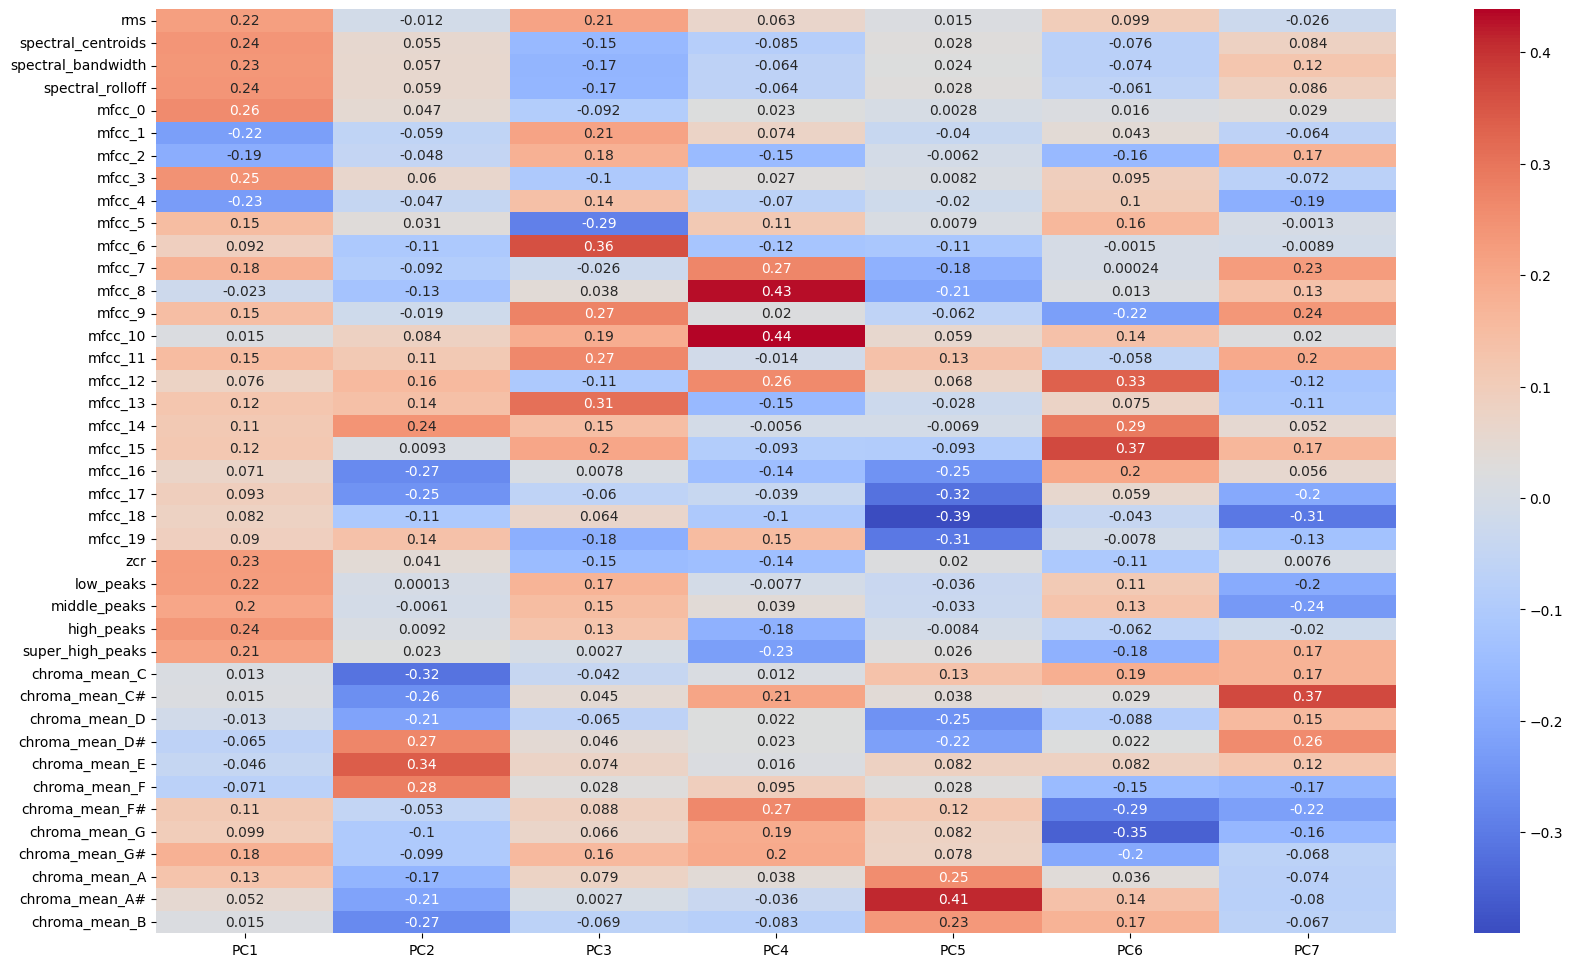

In [8]:
#主成負荷量を計算
#ローディングスコアの表示
loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f'PC{i}' for i in range(1, len(pca.components_) + 1)],
    index=col_num)
plt.figure(figsize=(20, 12))
sns.heatmap(loadings, annot=True, cmap='coolwarm')
plt.show()

C:\Users\koyamaharuki\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 20491 (\N{CJK UNIFIED IDEOGRAPH-500B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\koyamaharuki\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 20154 (\N{CJK UNIFIED IDEOGRAPH-4EBA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\koyamaharuki\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 12463 (\N{KATAKANA LETTER KU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\koyamaharuki\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 12521 (\N{KATAKANA LETTER RA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\koyamaharuki\AppData\Lo

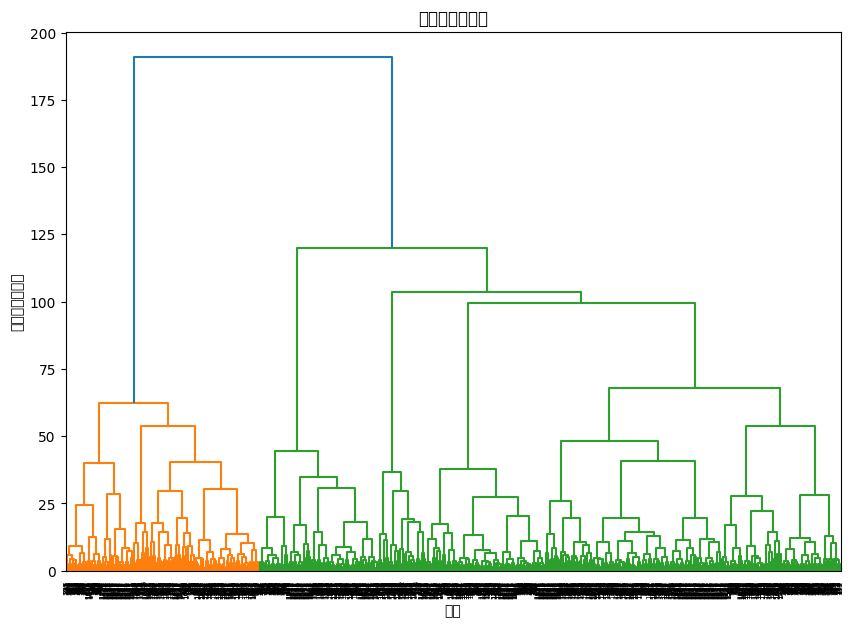

In [9]:
# データから距離行列を計算してlinkageを実行
import scipy.cluster.hierarchy as sch
from scipy.cluster.hierarchy import dendrogram, linkage
Z = linkage(df_pca, method='ward')

# デンドログラムの表示
plt.figure(figsize=(10, 7))
dendrogram(Z)
plt.title('デンドログラム')
plt.xlabel('個人')
plt.ylabel('クラスタ間距離')
plt.show()


cluster_den
5    660
1    432
4    264
2    264
3    108
Name: count, dtype: int64


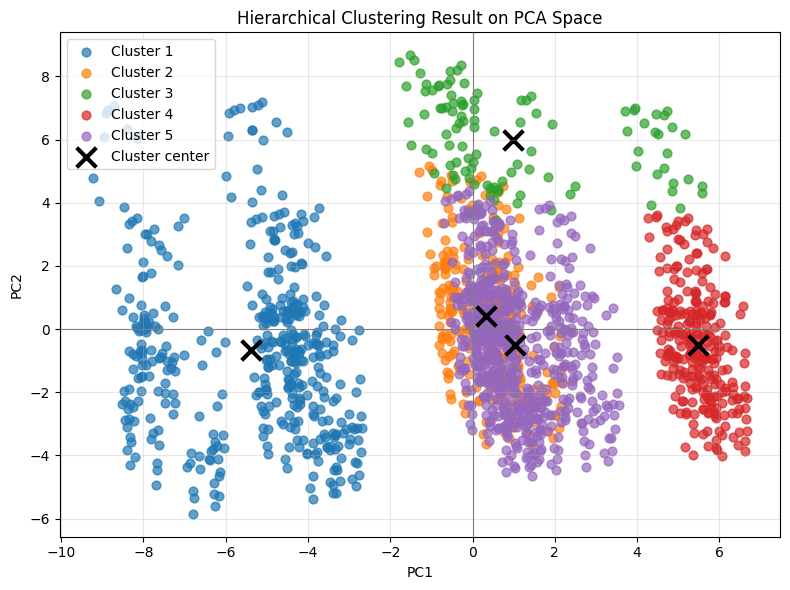

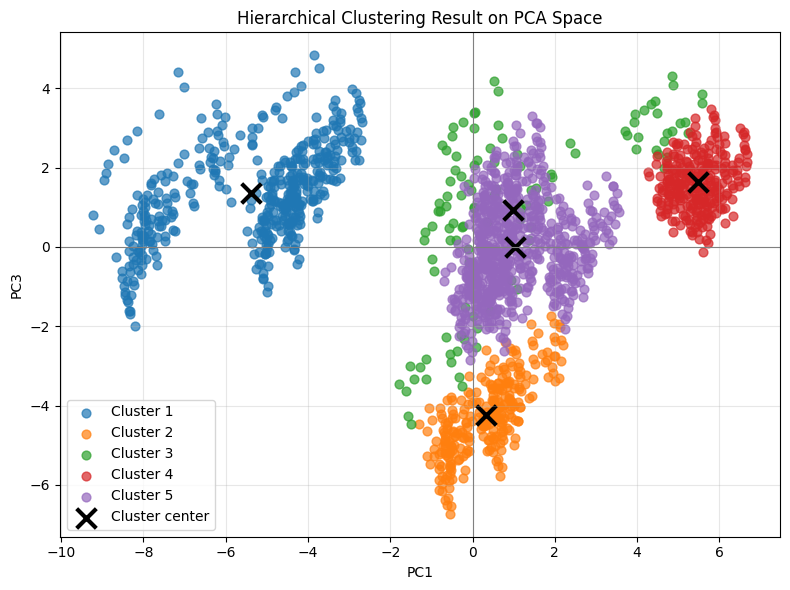

In [10]:
from scipy.cluster.hierarchy import linkage, fcluster

# クラスタ分けするしきい値を決める。3分割したいので25に設定。
threshold = 75
linkage_array = linkage(df_pca, method='ward', metric='euclidean')

# クラスタリング結果の値を取得
df_final['cluster_den'] = fcluster(linkage_array, threshold, criterion='distance')
print(df_final['cluster_den'].value_counts())



# =========================
# PC1-PC2にクラスタ結果をプロット
# =========================

plt.figure(figsize=(8, 6))

for cluster_id, group in df_final.groupby('cluster_den'):
    plt.scatter(
        group['PC1'],
        group['PC2'],
        label=f'Cluster {cluster_id}',
        alpha=0.7,
        s=40
    )

# 各クラスタの重心を表示
centers = df_final.groupby('cluster_den')[['PC1', 'PC2']].mean()

plt.scatter(
    centers['PC1'],
    centers['PC2'],
    marker='x',
    s=200,
    linewidths=3,
    color='black',
    label='Cluster center'
)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Hierarchical Clustering Result on PCA Space')
plt.axhline(0, color='gray', linewidth=0.8)
plt.axvline(0, color='gray', linewidth=0.8)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# =========================
# PC1-PC2にクラスタ結果をプロット
# =========================

plt.figure(figsize=(8, 6))

for cluster_id, group in df_final.groupby('cluster_den'):
    plt.scatter(
        group['PC1'],
        group['PC3'],
        label=f'Cluster {cluster_id}',
        alpha=0.7,
        s=40
    )

# 各クラスタの重心を表示
centers = df_final.groupby('cluster_den')[['PC1', 'PC3']].mean()

plt.scatter(
    centers['PC1'],
    centers['PC3'],
    marker='x',
    s=200,
    linewidths=3,
    color='black',
    label='Cluster center'
)

plt.xlabel('PC1')
plt.ylabel('PC3')
plt.title('Hierarchical Clustering Result on PCA Space')
plt.axhline(0, color='gray', linewidth=0.8)
plt.axvline(0, color='gray', linewidth=0.8)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
import numpy as np
import pandas as pd

# =========================
# 1. PCAスコアをdf_finalに追加
# =========================

df_select = df_final.copy()

n_pc = 7  # クラスタリングに使った主成分数に合わせる
pc_cols = [f"PC{i}" for i in range(1, n_pc + 1)]

for i, col in enumerate(pc_cols):
    df_select[col] = df_pca.iloc[:, i].values


# =========================
# 2. 各クラスターを中心からの距離順に3等分し、各領域から4曲選出
# =========================

def select_songs_per_cluster_by_region(
    data,
    pc_cols,
    cluster_col="cluster_den",
    songs_per_region=4,
    random_seed=42
):
    regions = ("center", "middle", "outer")
    rng = np.random.default_rng(random_seed)
    selected_rows = []

    for cluster_id, cluster_df in data.groupby(cluster_col):
        cluster_df = cluster_df.copy()

        if len(cluster_df) < songs_per_region * len(regions):
            raise ValueError(f"Cluster {cluster_id} has fewer than 12 songs.")

        X = cluster_df[pc_cols].values
        center = X.mean(axis=0)

        cluster_df["distance_to_center"] = np.linalg.norm(X - center, axis=1)
        cluster_df = cluster_df.sort_values(
            ["distance_to_center", "filename"], kind="stable"
        ).reset_index(drop=True)

        # 距離順位の0〜33%、33〜66%、66〜100%に相当する3領域
        for level, positions in zip(regions, np.array_split(np.arange(len(cluster_df)), 3)):
            if len(positions) < songs_per_region:
                raise ValueError(f"Cluster {cluster_id}, {level}: fewer than 4 songs.")
            chosen_positions = rng.choice(positions, size=songs_per_region, replace=False)
            selected_row = cluster_df.iloc[chosen_positions].copy()
            selected_row["target_level"] = level
            selected_row["distance_rank_percent"] = (chosen_positions + 1) / len(cluster_df) * 100

            selected_rows.append(selected_row)

    return pd.concat(selected_rows, axis=0, ignore_index=True)


selected_songs = select_songs_per_cluster_by_region(
    data=df_select,
    pc_cols=pc_cols,
    cluster_col="cluster_den",
    songs_per_region=4,
    random_seed=42
)

display(selected_songs.groupby(["cluster_den", "target_level"]).size().unstack())
print(f"Total selected: {len(selected_songs)} songs")
selected_songs

target_level,center,middle,outer
cluster_den,,,
1,4,4,4
2,4,4,4
3,4,4,4
4,4,4,4
5,4,4,4


Total selected: 60 songs


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,filename,harmony,melody,rhythm,cluster_den,distance_to_center,target_level,distance_rank_percent
0,-4.875591,-1.141288,0.220946,-1.343233,-1.828161,1.460394,-0.361388,4563中_上昇2_drumn小,4563中,上昇2,drumn小,1,2.927525,center,14.814815
1,-4.396028,-0.305332,1.672231,0.823101,-1.106679,-0.926666,-0.304036,4563小_山型6_drumn小,4563小,山型6,drumn小,1,1.972924,center,3.009259
2,-3.556678,-1.532594,1.712346,1.184740,-2.341166,0.650391,-0.621106,4536小_上昇4_shuffle小,4536小,上昇4,shuffle小,1,3.188416,center,21.759259
3,-4.421205,-1.012316,0.851576,-0.522222,-2.858374,1.664177,0.012513,4563大_上昇4_shuffle小,4563大,上昇4,shuffle小,1,3.351311,center,25.462963
4,-3.473525,-3.832320,2.307072,1.769159,0.842242,0.791132,1.055559,4361小_下降2_drumn小,4361小,下降2,drumn小,1,4.452051,middle,56.250000
5,-8.067516,0.765009,0.797277,-0.095262,-0.699789,-1.963775,-0.387143,4563大_山型2_half小,4563大,山型2,half小,1,3.871768,middle,40.046296
6,-6.253425,-3.578382,1.881706,1.768836,1.196587,-0.359565,0.160233,4361中_下降2_half小,4361中,下降2,half小,1,3.764486,middle,36.574074
7,-3.989636,2.731501,2.672972,0.817146,-0.712613,1.566164,-1.238228,4536小_一定3_shuffle小,4536小,一定3,shuffle小,1,4.302875,middle,50.925926
8,-7.735561,3.166482,1.703330,1.822113,-0.008858,-3.691583,-2.098431,4536中_一定5_half小,4536中,一定5,half小,1,6.478315,outer,90.277778
9,-6.081350,-2.050291,3.069801,3.618510,1.946798,-2.928057,0.231688,4361中_山型2_half小,4361中,山型2,half小,1,5.613847,outer,83.796296


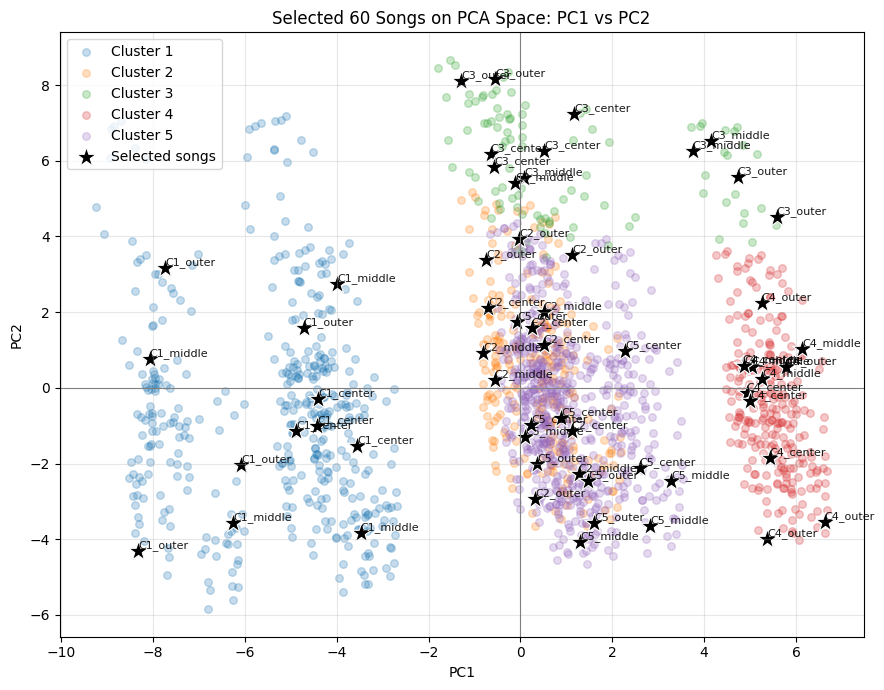

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))

# =========================
# 1. 全曲をクラスタごとに薄く表示
# =========================

for cluster_id, group in df_select.groupby("cluster_den"):
    plt.scatter(
        group["PC1"],
        group["PC2"],
        label=f"Cluster {cluster_id}",
        alpha=0.25,
        s=30
    )

# =========================
# 2. 選出した楽曲を強調表示
# =========================

plt.scatter(
    selected_songs["PC1"],
    selected_songs["PC2"],
    color="black",
    marker="*",
    s=220,
    label="Selected songs",
    edgecolors="white",
    linewidths=0.8
)

# =========================
# 3. 選出曲にラベルを付ける
# =========================

for _, row in selected_songs.iterrows():
    label = f"C{row['cluster_den']}_{row['target_level']}"

    plt.text(
        row["PC1"],
        row["PC2"],
        label,
        fontsize=8,
        ha="left",
        va="bottom",
        alpha=0.9
    )

# =========================
# 4. 図の装飾
# =========================

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(f"Selected {len(selected_songs)} Songs on PCA Space: PC1 vs PC2")
plt.axhline(0, color="gray", linewidth=0.8)
plt.axvline(0, color="gray", linewidth=0.8)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

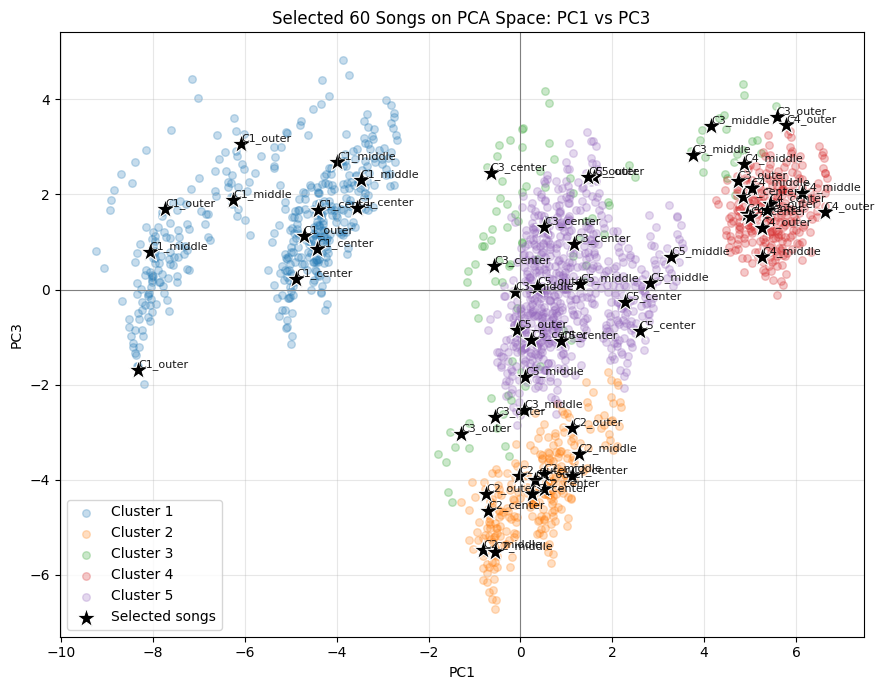

In [13]:
plt.figure(figsize=(9, 7))

# =========================
# 1. 全曲をクラスタごとに薄く表示
# =========================

for cluster_id, group in df_select.groupby("cluster_den"):
    plt.scatter(
        group["PC1"],
        group["PC3"],
        label=f"Cluster {cluster_id}",
        alpha=0.25,
        s=30
    )

# =========================
# 2. 選出した楽曲を強調表示
# =========================

plt.scatter(
    selected_songs["PC1"],
    selected_songs["PC3"],
    color="black",
    marker="*",
    s=220,
    label="Selected songs",
    edgecolors="white",
    linewidths=0.8
)

# =========================
# 3. 選出曲にラベルを付ける
# =========================

for _, row in selected_songs.iterrows():
    label = f"C{row['cluster_den']}_{row['target_level']}"

    plt.text(
        row["PC1"],
        row["PC3"],
        label,
        fontsize=8,
        ha="left",
        va="bottom",
        alpha=0.9
    )

# =========================
# 4. 図の装飾
# =========================

plt.xlabel("PC1")
plt.ylabel("PC3")
plt.title(f"Selected {len(selected_songs)} Songs on PCA Space: PC1 vs PC3")
plt.axhline(0, color="gray", linewidth=0.8)
plt.axvline(0, color="gray", linewidth=0.8)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
meta_cols = [
    "harmony",
    "rhythm",
    "melody"
]

for col in meta_cols:
    print("=" * 50)
    print(col)
    print(selected_songs[col].value_counts().sort_index())

harmony
harmony
4361中    6
4361大    5
4361小    4
4536中    5
4536大    6
4536小    4
4563中    3
4563大    7
4563小    4
6451中    7
6451大    4
6451小    5
Name: count, dtype: int64
rhythm
rhythm
2x中         10
2x大          6
2x小          4
drumn中       2
drumn大       3
drumn小       3
half中        6
half大        9
half小        5
shuffle中     3
shuffle大     5
shuffle小     4
Name: count, dtype: int64
melody
melody
一定0     12
一定3      6
一定5      4
上昇2      5
上昇3      5
上昇4      6
下降1      1
下降2      8
下降4      2
山型10     1
山型2      3
山型6      7
Name: count, dtype: int64


C:\Users\koyamaharuki\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 20013 (\N{CJK UNIFIED IDEOGRAPH-4E2D}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\koyamaharuki\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 22823 (\N{CJK UNIFIED IDEOGRAPH-5927}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\koyamaharuki\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 23567 (\N{CJK UNIFIED IDEOGRAPH-5C0F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


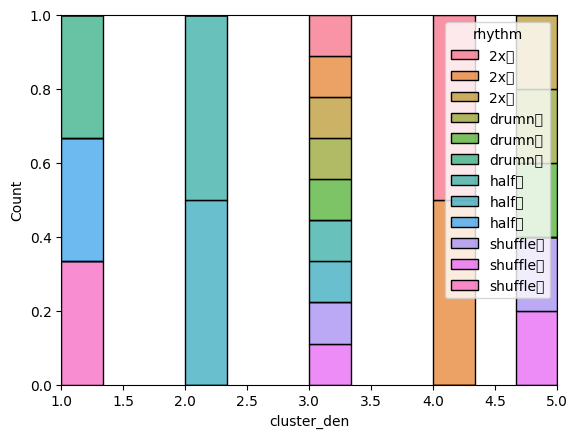

In [15]:
clus = df_final['cluster_den']
harm = df_final['harmony']
melody = df_final['melody']
rhythm = df_final['rhythm']

sns.histplot(data=df_final, x='cluster_den', hue='rhythm', multiple='fill')
plt.show()

In [16]:
display(selected_songs['filename'])

0       4563中_上昇2_drumn小
1       4563小_山型6_drumn小
2     4536小_上昇4_shuffle小
3     4563大_上昇4_shuffle小
4       4361小_下降2_drumn小
5        4563大_山型2_half小
6        4361中_下降2_half小
7     4536小_一定3_shuffle小
8        4536中_一定5_half小
9        4361中_山型2_half小
10       6451大_上昇2_half小
11    6451中_一定3_shuffle小
12       6451小_山型6_half大
13       4536中_下降4_half中
14       4563大_山型6_half大
15       4536大_下降4_half大
16       4563大_下降2_half中
17       4536大_山型6_half大
18       6451中_山型6_half中
19       4361大_下降2_half大
20       4563大_一定3_half大
21       4536小_一定5_half大
22       4361大_上昇4_half中
23       4536大_山型2_half中
24         4563大_一定0_2x小
25    6451中_一定0_shuffle中
26      4536小_一定0_drumn大
27    4536大_一定0_shuffle大
28         4563大_一定0_2x中
29         4563小_一定0_2x中
30       6451小_一定0_half大
31      6451中_一定0_drumn大
32         6451中_一定0_2x大
33       4536大_一定0_half大
34         4361中_一定0_2x大
35       4563小_一定0_half中
36         6451小_上昇3_2x中
37         4563中_上昇4_2x中
38         4536中_上昇3_2x中
39         4563小_下降2_2x中
